In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

Model opisujący zależność między pompowaniem, a energią 

In [28]:
%load_ext autoreload
%autoreload 2


from przygotowanie_danych_zuzycia_energii import przygotuj_dane_zuzycia_energii

models_path = Path.cwd().parents[0]
sys.path.append(str(models_path / "Predykcja przepompowanych ścieków"))

from przygotowanie_danych_przepompowania import przygotuj_dane_przepompowania_z_opadami



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
X_energia, Y_energia = przygotuj_dane_zuzycia_energii()
X_przeplyw, Y_przeplyw = przygotuj_dane_przepompowania_z_opadami()


In [30]:
features = [
    # Kalendarz
    "hour", "dayofweek", "month",

    # Opady
    "opad_1h", "opad_6h", "opad_12h",
    "opad_24h", "opad_48h", "opad_168h",
    "h_od_deszczu",
]

X = X_energia[features].join(Y_przeplyw)
y = Y_energia

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]


In [31]:


# Dwa modele LightGBM:
# 1. Pierwszy przewiduje typową ilość przepompowanych ścieków
# 2. Drugi wyznacza górną granicę oczekiwanego pompowania (Q97) - uwzględniając opady
# Przekroczenie Q97 wskazuje potencjalnie nietypowy dodatkowy dopływ

lgbm = LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                     num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)

lgbm_q = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [32]:
y_pred_test = lgbm.predict(X_test)
q_test = lgbm_q.predict(X_test)

prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values

print("MAE modelu:  ", round(mean_absolute_error(y_test, y_pred_test), 2))
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))

MAE modelu:   0.52
MAE baseline: 1.48


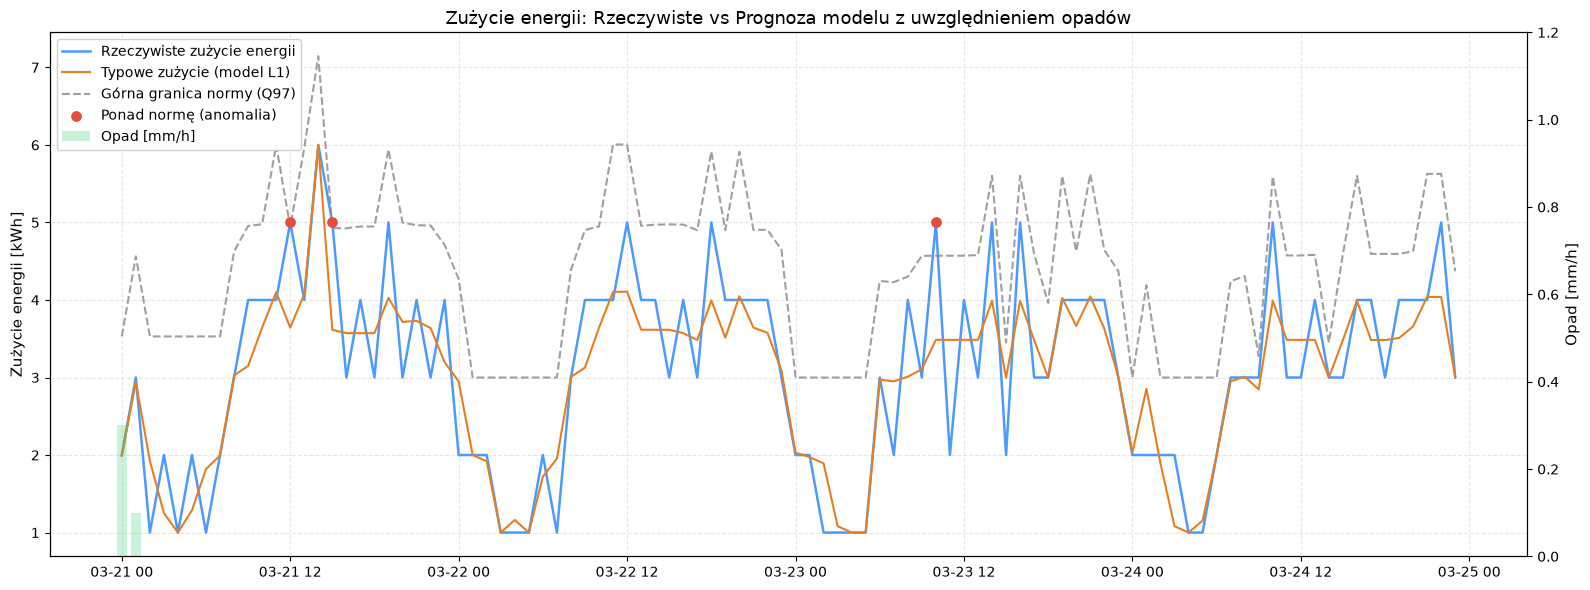

In [33]:
results_test = pd.DataFrame(
    {
        "rzeczywiste": y_test,
        "prognoza": y_pred_test,
        "q97": q_test,
        "opad": X_test["opad_1h"],
    },
    index=y_test.index,
)

sample = results_test.loc["2026-03-21":"2026-03-24"]

# punkty ponad normę
anomalie = sample[sample["rzeczywiste"] > sample["q97"]]

fig, ax1 = plt.subplots(figsize=(16, 6))

# Oś 1: Zużycie energii
ax1.plot(
    sample.index,
    sample["rzeczywiste"],
    label="Rzeczywiste zużycie energii",
    color="#4C9AFF",
    linewidth=1.8,
)
ax1.plot(
    sample.index,
    sample["prognoza"],
    label="Typowe zużycie (model L1)",
    color="#E67E22",
    linewidth=1.5,
)
if "q97" in sample.columns:
  ax1.plot(
      sample.index,
      sample["q97"],
      label="Górna granica normy (Q97)",
      color="#888888",
      linestyle="--",
      alpha=0.8,
  )
  if len(anomalie) > 0:
    ax1.scatter(
        anomalie.index,
        anomalie["rzeczywiste"],
        color="#E74C3C",
        s=45,
        zorder=5,
        label="Ponad normę (anomalia)",
    )

ax1.set_ylabel("Zużycie energii [kWh]", fontsize=11)
ax1.set_title(
    "Zużycie energii: Rzeczywiste vs Prognoza modelu z uwzględnieniem opadów",
    fontsize=13,
)
ax1.grid(True, linestyle="--", alpha=0.3)

# Oś 2: Słupki opadów deszczu w tle
ax2 = ax1.twinx()
ax2.bar(
    sample.index,
    sample["opad"],
    width=0.03,
    color="#2ECC71",
    alpha=0.25,
    label="Opad [mm/h]",
)
ax2.set_ylabel("Opad [mm/h]", fontsize=11)
max_opad = sample["opad"].dropna().max() if not sample["opad"].dropna().empty else 0
ax2.set_ylim(0, max(max_opad * 4, 1.0))

# Połączenie legend z obu osi w jedno okno
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", framealpha=0.9)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# SHAP

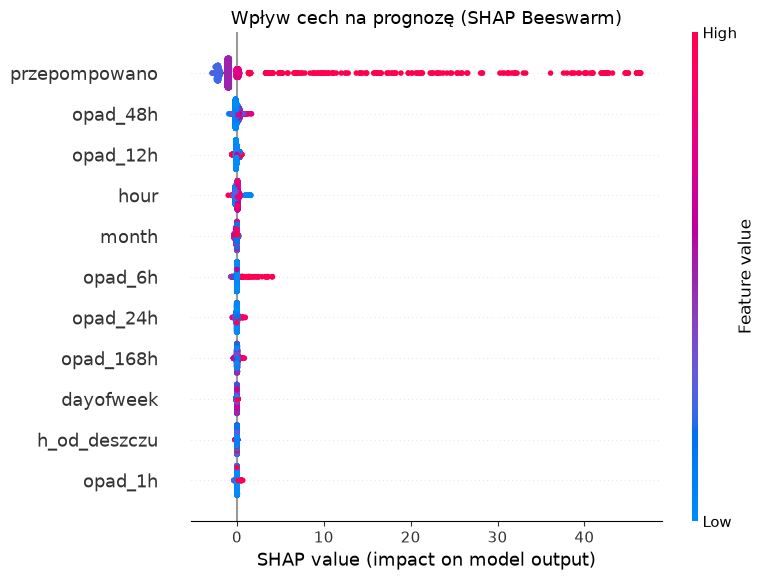

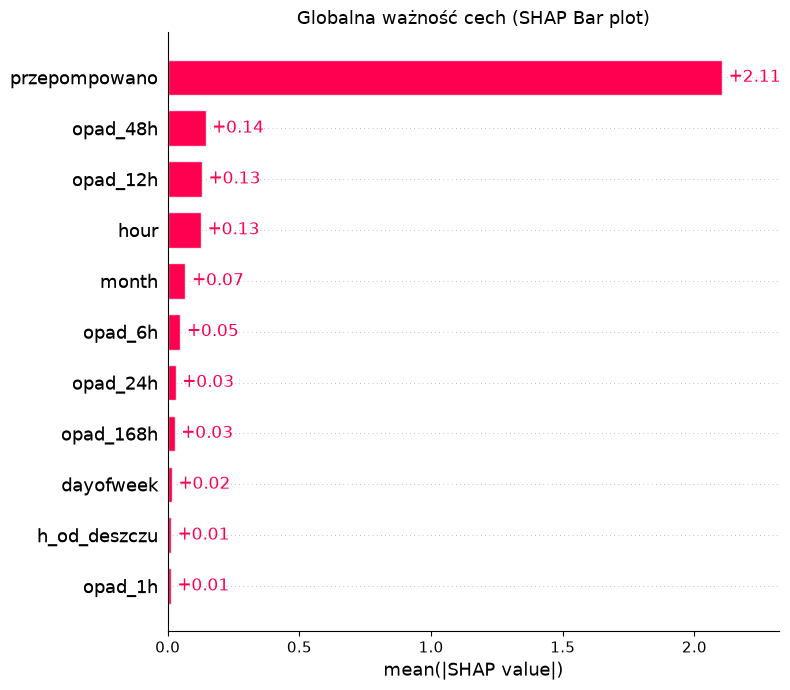

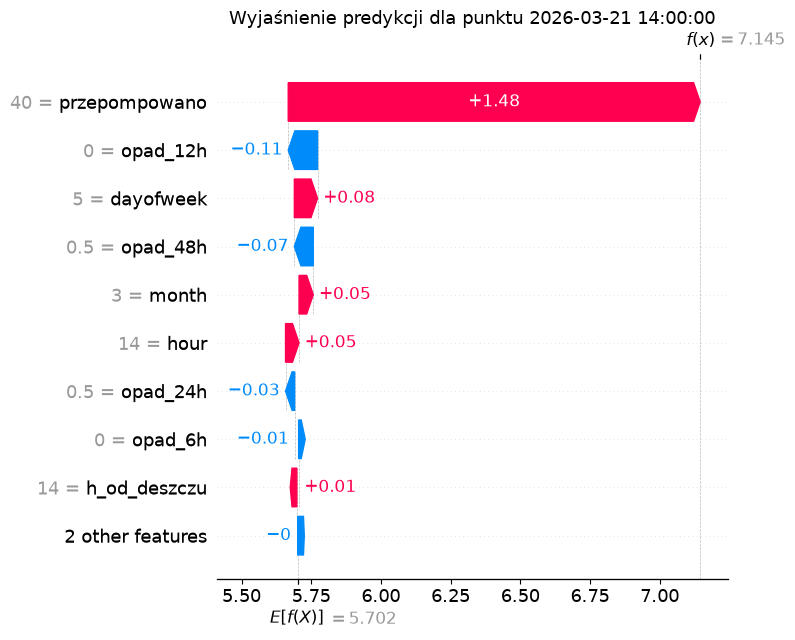

In [34]:
from SHAP import generate_shap_from_tree

generate_shap_from_tree(lgbm_q,X_test,date_with_time="2026-03-21 14:00:00")